# Q1: Which past indicators predict future KSI crashes?



Builds a validated KSI risk score for every crash site (issue #19). All logic lives in the layers; this notebook only wires them together and plots the results.



**Design decisions** (each one is set in config):

- **Sites:** peak-radius clusters of geocoded crash locations (every location within 100 ft of the busiest unclaimed one, so sites cannot chain along corridors), built only from crashes before 2024 (`SiteConfig`).

- **Outcome:** KSI crashes per site-year. KSI means a death, or a severe-injury proxy from the persons table's `complaint`/`emotional_status`, because public data has no "seriously injured" field (`CrashConfig`).

- **Predictors:** 3-year lagged crash counts entered as `log1p`, plus highway share and camera flags (`PanelConfig`).

- **Validation:** expanding window. For each test year (2024, 2025), fit on earlier years and score that year. Metrics are reported for all sites and for non-highway sites (`ValidationConfig`).

In [1]:
import logging

import sys

from pathlib import Path



sys.path.append("..")



import matplotlib.pyplot as plt

import numpy as np

import pandas as pd



from model.count_models import HistoryRanker, NegativeBinomialModel

from preprocessing.panel import load_panel

from validation.validate import ValidationConfig, evaluate, poisson_interval, top_k_totals



logging.basicConfig(level=logging.INFO, format="%(message)s")

pd.set_option("display.precision", 3)



# Chart styling: blue for the model, orange for current practice / KSI, gray ink for text

MODEL, PRACTICE, CONTEXT = "#2a78d6", "#eb6834", "#c9c8c2"

INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

plt.rcParams.update({

    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,

    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "text.color": INK,

    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False,

    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",

    "grid.linewidth": 0.6, "axes.titlesize": 12, "axes.titleweight": "bold",

    "axes.titlelocation": "left", "font.size": 10,

})

In [2]:
panel, scoring, sites = load_panel()

panel.shape, scoring.shape, sites.shape

clean_crashes: dropped 0 crashes before 2017-01-01


drop_ungeocoded: dropped 95967 of 1311313 crashes (7.3%) with missing or out-of-NYC coordinates


flag_highway: 146081 of 1215346 crashes flagged as highway


flag_ksi: 25873 KSI crashes (2107 with a death); 3533 crashes had no person records


build_site_points: 1013673 crashes before 2024-01-01 at 210488 unique points -> 89073 sites


assign_sites: 18031 crashes unassigned (18031 of 201673 on/after 2024-01-01)


count_site_years: 15 crashes with missing injury counts treated as 0


assign_cameras: 4308 of 4610 cameras matched to a site within 150 ft


load_panel: 534438 site-years for 89073 sites


((534438, 33), (89073, 33), (89073, 8))

## Model ladder

Rung 1 is current practice (rank by past KSI). If a crash-history model ranks better, past KSI alone is too sparse a signal.



The crash-history model can use one of two sets of counts:

- **Nested** (`ksi`, `injury`, `crashes`, ...): every KSI crash is also an injury crash and also a crash, so each coefficient means "more of this type *holding the broader counts fixed*" (a severity-mix effect), and the overlapping features are strongly correlated.

- **Severity tiers** (`pdo`, `injury_nonsevere`, `ksi_nonfatal`, `fatal`): each crash counts in exactly one tier, so each coefficient means "more past crashes of this type". This is the version we interpret.



Both are legitimate and predict about equally well; the tiers just make the coefficients readable.

In [3]:
def log1p_lags(cols):

    return [f"log1p_{c}_lag3" for c in cols]



ROAD_USERS = ["ped_injured", "cyc_injured"]

NESTED = log1p_lags(["ksi", "fatal", "injury", "crashes"] + ROAD_USERS)

TIERS = log1p_lags(["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal"] + ROAD_USERS)

CONTEXT_VARS = ["highway_share", "rlc_active", "speed_active"]



ladder = {

    "1 past KSI (baseline)": lambda: HistoryRanker("ksi_lag3", n_years=3),

    "2 past injury crashes": lambda: HistoryRanker("injury_lag3", n_years=3),

    "3 NB: KSI history": lambda: NegativeBinomialModel(["log1p_ksi_lag3"]),

    "4 NB: crash history (nested)": lambda: NegativeBinomialModel(NESTED),

    "5 NB: crash history (tiers)": lambda: NegativeBinomialModel(TIERS),

    "6 NB: tiers + highway, cameras": lambda: NegativeBinomialModel(TIERS + CONTEXT_VARS),

}

config = ValidationConfig()



results, calibrations, predictions = [], [], {}

for name, make_model in ladder.items():

    metrics, calibration, predictions[name] = evaluate(make_model, panel, config)

    results.append(metrics.assign(model=name))

    calibrations.append(calibration.assign(model=name))



# Sensitivity: drop every site that ever had a camera

no_camera = panel[~panel["camera_site"]]

for name in ["1 past KSI (baseline)", "5 NB: crash history (tiers)"]:

    metrics, _, _ = evaluate(ladder[name], no_camera, config)

    results.append(metrics.assign(model=f"no-camera sites: {name}"))



results = pd.concat(results)

calibrations = pd.concat(calibrations)

### Share of next year's KSI crashes captured by the top-k sites (mean of test years)

In [4]:
capture = (

    results[results["metric"] == "top_k_capture"]

    .pivot_table(index=["scope", "model"], columns="k", values="value")

)

capture

k                                                         50.0    100.0   \
scope       model                                                          
all         1 past KSI (baseline)                          0.012   0.020   
            2 past injury crashes                          0.013   0.025   
            3 NB: KSI history                              0.012   0.020   
            4 NB: crash history (nested)                   0.013   0.026   
            5 NB: crash history (tiers)                    0.012   0.026   
            6 NB: tiers + highway, cameras                 0.013   0.026   
            no-camera sites: 1 past KSI (baseline)         0.011   0.018   
            no-camera sites: 5 NB: crash history (tiers)   0.015   0.028   
non_highway 1 past KSI (baseline)                          0.013   0.022   
            2 past injury crashes                          0.015   0.029   
            3 NB: KSI history                              0.013   0.022   
            4 NB: crash history (nested)                   0.015   0.029   
            5 NB: crash history (tiers)                    0.015   0.030   
            6 NB: tiers + highway, cameras                 0.015   0.029   
            no-camera sites: 1 past KSI (baseline)         0.012   0.019   
            no-camera sites: 5 NB: crash history (tiers)   0.017   0.027   

k                                                         250.0   500.0   \
scope       model                                                          
all         1 past KSI (baseline)                          0.040   0.064   
            2 past injury crashes                          0.057   0.095   
            3 NB: KSI history                              0.040   0.064   
            4 NB: crash history (nested)                   0.055   0.096   
            5 NB: crash history (tiers)                    0.055   0.098   
            6 NB: tiers + highway, cameras                 0.056   0.097   
            no-camera sites: 1 past KSI (baseline)         0.036   0.059   
            no-camera sites: 5 NB: crash history (tiers)   0.057   0.097   
non_highway 1 past KSI (baseline)                          0.043   0.068   
            2 past injury crashes                          0.057   0.097   
            3 NB: KSI history                              0.043   0.068   
            4 NB: crash history (nested)                   0.058   0.100   
            5 NB: crash history (tiers)                    0.058   0.100   
            6 NB: tiers + highway, cameras                 0.058   0.101   
            no-camera sites: 1 past KSI (baseline)         0.036   0.061   
            no-camera sites: 5 NB: crash history (tiers)   0.057   0.093   

k                                                         1000.0  
scope       model                                                 
all         1 past KSI (baseline)                          0.110  
            2 past injury crashes                          0.160  
            3 NB: KSI history                              0.110  
            4 NB: crash history (nested)                   0.157  
            5 NB: crash history (tiers)                    0.159  
            6 NB: tiers + highway, cameras                 0.160  
            no-camera sites: 1 past KSI (baseline)         0.101  
            no-camera sites: 5 NB: crash history (tiers)   0.154  
non_highway 1 past KSI (baseline)                          0.115  
            2 past injury crashes                          0.159  
            3 NB: KSI history                              0.115  
            4 NB: crash history (nested)                   0.161  
            5 NB: crash history (tiers)                    0.160  
            6 NB: tiers + highway, cameras                 0.161  
            no-camera sites: 1 past KSI (baseline)         0.097  
            no-camera sites: 5 NB: crash history (tiers)   0.148

### Fit: Poisson deviance (lower is better) and predicted / observed total KSI

In [5]:
(

    results[results["metric"] != "top_k_capture"]

    .pivot_table(index=["scope", "model"], columns="metric", values="value")

)

metric                                                    poisson_deviance  \
scope       model                                                            
all         1 past KSI (baseline)                                    0.568   
            2 past injury crashes                                    0.846   
            3 NB: KSI history                                        0.196   
            4 NB: crash history (nested)                             0.162   
            5 NB: crash history (tiers)                              0.164   
            6 NB: tiers + highway, cameras                           0.164   
            no-camera sites: 1 past KSI (baseline)                   0.531   
            no-camera sites: 5 NB: crash history (tiers)             0.154   
non_highway 1 past KSI (baseline)                                    0.527   
            2 past injury crashes                                    0.778   
            3 NB: KSI history                                        0.184   
            4 NB: crash history (nested)                             0.152   
            5 NB: crash history (tiers)                              0.154   
            6 NB: tiers + highway, cameras                           0.154   
            no-camera sites: 1 past KSI (baseline)                   0.490   
            no-camera sites: 5 NB: crash history (tiers)             0.145   

metric                                                    pred_to_obs_total  \
scope       model                                                             
all         1 past KSI (baseline)                                     1.003   
            2 past injury crashes                                    13.734   
            3 NB: KSI history                                         1.030   
            4 NB: crash history (nested)                              1.014   
            5 NB: crash history (tiers)                               1.010   
            6 NB: tiers + highway, cameras                            1.010   
            no-camera sites: 1 past KSI (baseline)                    1.001   
            no-camera sites: 5 NB: crash history (tiers)              1.012   
non_highway 1 past KSI (baseline)                                     1.027   
            2 past injury crashes                                    13.708   
            3 NB: KSI history                                         1.109   
            4 NB: crash history (nested)                              1.041   
            5 NB: crash history (tiers)                               1.039   
            6 NB: tiers + highway, cameras                            1.044   
            no-camera sites: 1 past KSI (baseline)                    1.024   
            no-camera sites: 5 NB: crash history (tiers)              1.043   

metric                                                    top_k_pred_to_obs  
scope       model                                                            
all         1 past KSI (baseline)                                     2.786  
            2 past injury crashes                                    19.548  
            3 NB: KSI history                                         1.418  
            4 NB: crash history (nested)                              1.519  
            5 NB: crash history (tiers)                               1.703  
            6 NB: tiers + highway, cameras                            1.657  
            no-camera sites: 1 past KSI (baseline)                    3.198  
            no-camera sites: 5 NB: crash history (tiers)              1.548  
non_highway 1 past KSI (baseline)                                     2.831  
            2 past injury crashes                                    17.833  
            3 NB: KSI history                                         1.402  
            4 NB: crash history (nested)                              1.433  
            5 NB: crash history (tiers)                               1.558  
  

## Figure 1: Which single past indicator best picks next year's KSI sites?

Each bar ranks sites by one past count alone (no model), then measures the share of next year's KSI crashes that falls in the top 1,000 sites. Looking at one indicator at a time sidesteps the overlap between counts. Orange marks current practice.

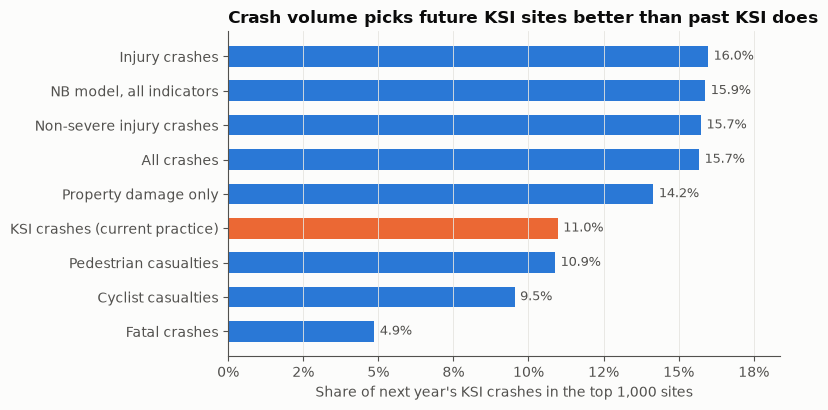

In [6]:
TOP_K = 1000

indicators = {

    "All crashes": "crashes_lag3",

    "Injury crashes": "injury_lag3",

    "Property damage only": "pdo_lag3",

    "Non-severe injury crashes": "injury_nonsevere_lag3",

    "Pedestrian casualties": "ped_injured_lag3",

    "Cyclist casualties": "cyc_injured_lag3",

    "KSI crashes (current practice)": "ksi_lag3",

    "Fatal crashes": "fatal_lag3",

}

single = {}

for label, col in indicators.items():

    m, _, _ = evaluate(lambda col=col: HistoryRanker(col), panel, config)

    single[label] = m.query("metric == 'top_k_capture' and scope == 'all' and k == @TOP_K")["value"].mean()

single["NB model, all indicators"] = capture.loc[("all", "5 NB: crash history (tiers)"), TOP_K]

single = pd.Series(single).sort_values()



fig, ax = plt.subplots(figsize=(8, 4.2))

colors = [PRACTICE if "current" in k else MODEL for k in single.index]

bars = ax.barh(single.index, single.values, color=colors, height=0.6)

ax.bar_label(bars, labels=[f"{v:.1%}" for v in single.values], padding=4, color=INK_2, fontsize=9)

ax.set_xlabel(f"Share of next year's KSI crashes in the top {TOP_K:,} sites")

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

ax.grid(axis="y", visible=False)

ax.set_xlim(0, single.max() * 1.15)

ax.set_title("Crash volume picks future KSI sites better than past KSI does")

fig.tight_layout()

## Figure 2: Which indicators carry the signal, given the others?

Rate ratios from the severity-tier model fit on every year, with standard errors clustered by site. Because features enter as `log1p`, each ratio is shown **per doubling** of the past count: a ratio of 1.3 means a site with twice as many past crashes of that type expects about 30% more KSI next year, holding the other types fixed. Bars are 95% intervals; 1 means no effect. Orange marks the KSI tiers.

In [7]:
final = NegativeBinomialModel(TIERS).fit(panel, panel["ksi"], groups=panel["site_id"])

coefs = final.coefficients()

coefs.loc[TIERS]

,coef,rate_ratio,ci_low,ci_high,p_value
log1p_pdo_lag3,0.487,1.628,1.581,1.676,8.409e-233
log1p_injury_nonsevere_lag3,0.740,2.095,2.022,2.171,0.000e+00
log1p_ksi_nonfatal_lag3,0.105,1.111,1.057,1.167,3.399e-05
log1p_fatal_lag3,0.044,1.045,0.921,1.187,4.926e-01
log1p_ped_injured_lag3,0.111,1.117,1.081,1.155,4.759e-11
log1p_cyc_injured_lag3,0.180,1.198,1.154,1.243,2.451e-21


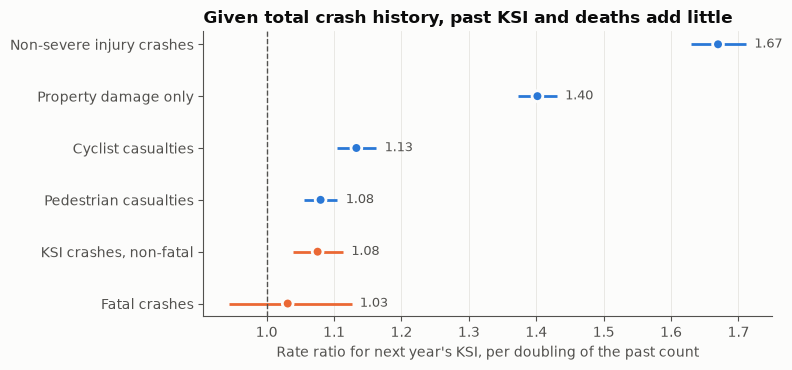

In [8]:
labels = {

    "log1p_pdo_lag3": "Property damage only",

    "log1p_injury_nonsevere_lag3": "Non-severe injury crashes",

    "log1p_ksi_nonfatal_lag3": "KSI crashes, non-fatal",

    "log1p_fatal_lag3": "Fatal crashes",

    "log1p_ped_injured_lag3": "Pedestrian casualties",

    "log1p_cyc_injured_lag3": "Cyclist casualties",

}

ci = final.result_.conf_int().loc[TIERS]

per_doubling = pd.DataFrame({

    "rr": 2 ** coefs.loc[TIERS, "coef"], "low": 2 ** ci[0], "high": 2 ** ci[1],

}).rename(index=labels).sort_values("rr")



fig, ax = plt.subplots(figsize=(8, 3.8))

y = np.arange(len(per_doubling))

color = np.where(per_doubling.index.str.contains("KSI|Fatal"), PRACTICE, MODEL)

ax.hlines(y, per_doubling["low"], per_doubling["high"], color=color, linewidth=2)

ax.scatter(per_doubling["rr"], y, color=color, s=60, zorder=3, edgecolor=SURFACE, linewidth=2)

for yi, (_, r) in zip(y, per_doubling.iterrows()):

    ax.annotate(f"{r['rr']:.2f}", (r["high"], yi), xytext=(6, 0), textcoords="offset points",

                va="center", fontsize=9, color=INK_2)

ax.axvline(1, color=INK_2, linewidth=1, linestyle="--")

ax.set_yticks(y, per_doubling.index)

ax.grid(axis="y", visible=False)

ax.set_xlabel("Rate ratio for next year's KSI, per doubling of the past count")

ax.set_title("Given total crash history, past KSI and deaths add little")

fig.tight_layout()

## Figure 3: Are the predicted counts right? (calibration by risk band)

Sites are binned by percentile of predicted risk, with **narrow bins at the top**, where watch lists are drawn: the last bin is the top 0.1% (about 89 sites per year). Equal-size deciles would hide the top sites inside a bin of ~8,900 mostly moderate-risk sites. Both test years are pooled.



Each point is observed ÷ predicted KSI for the bin: 1 is perfect, below 1 means the model over-predicted. Bars are 95% Poisson intervals on the observed count; the labels give observed / predicted KSI crashes.

,band,n,pred_total,obs_total,ratio,low,high
0,0–50,89074,871.457,478.0,0.549,0.500,0.600
1,50–80,53444,984.420,911.0,0.925,0.866,0.988
2,80–90,17814,722.574,948.0,1.312,1.230,1.398
3,90–95,8908,657.100,894.0,1.361,1.273,1.453
4,95–98,5344,701.461,827.0,1.179,1.100,1.262
5,98–99,1782,403.277,412.0,1.022,0.925,1.125
6,99–99.5,890,308.965,309.0,1.000,0.892,1.118
7,99.5–99.9,712,413.137,343.0,0.830,0.745,0.923
8,99.9–100,178,234.649,120.0,0.511,0.424,0.612


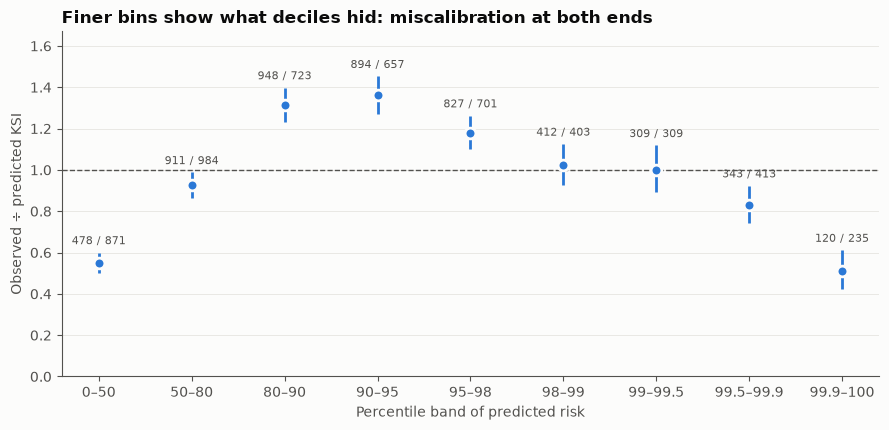

In [9]:
cal = (

    calibrations.query("model == '5 NB: crash history (tiers)' and scope == 'all'")

    .groupby(["bin", "q_low", "q_high"])[["n", "pred_total", "obs_total"]].sum()

    .reset_index()

)

low, high = poisson_interval(cal["obs_total"])

cal = cal.assign(

    ratio=cal["obs_total"] / cal["pred_total"],

    low=low / cal["pred_total"],

    high=high / cal["pred_total"],

    band=[f"{lo * 100:g}–{hi * 100:g}" for lo, hi in zip(cal["q_low"], cal["q_high"])],

)



fig, ax = plt.subplots(figsize=(9, 4.4))

x = np.arange(len(cal))

ax.vlines(x, cal["low"], cal["high"], color=MODEL, linewidth=2)

ax.scatter(x, cal["ratio"], color=MODEL, s=60, zorder=3, edgecolor=SURFACE, linewidth=2)

for xi, r in zip(x, cal.itertuples()):

    ax.annotate(f"{r.obs_total:.0f} / {r.pred_total:.0f}", (xi, r.high), xytext=(0, 6),

                textcoords="offset points", ha="center", fontsize=8, color=INK_2)

ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)

ax.set_xticks(x, cal["band"])

ax.set_ylim(0, max(1.6, cal["high"].max() * 1.15))

ax.grid(axis="x", visible=False)

ax.set_xlabel("Percentile band of predicted risk")

ax.set_ylabel("Observed ÷ predicted KSI")

ax.set_title("Finer bins show what deciles hid: miscalibration at both ends")

fig.tight_layout()

cal[["band", "n", "pred_total", "obs_total", "ratio", "low", "high"]]

## Figure 4: How far down the list can the predicted numbers be trusted?

For each list length k, this compares total predicted with total observed KSI among the top-k sites (both test years summed). The orange line is current practice's implicit forecast (past 3-year KSI ÷ 3). Shaded bands are 95% Poisson intervals. A line below 1 means the list's expected count overstates what happened.

,model,k,pred,obs,ratio,low,high
0,5 NB: crash history (tiers),10,54.25,17.00,0.31,0.18,0.50
9,5 NB: crash history (tiers),49,158.39,65.00,0.41,0.32,0.52
13,5 NB: crash history (tiers),100,253.31,134.00,0.53,0.44,0.63
19,5 NB: crash history (tiers),289,498.26,333.00,0.67,0.60,0.74
26,5 NB: crash history (tiers),1000,1017.39,832.00,0.82,0.76,0.88
29,5 NB: crash history (tiers),1701,1330.17,1156.00,0.87,0.82,0.92
39,5 NB: crash history (tiers),10000,2836.37,3062.39,1.08,1.04,1.12
40,1 past KSI (baseline),10,41.67,16.76,0.40,0.23,0.65
49,1 past KSI (baseline),49,161.33,61.14,0.38,0.29,0.49
53,1 past KSI (baseline),100,291.67,106.69,0.37,0.30,0.44


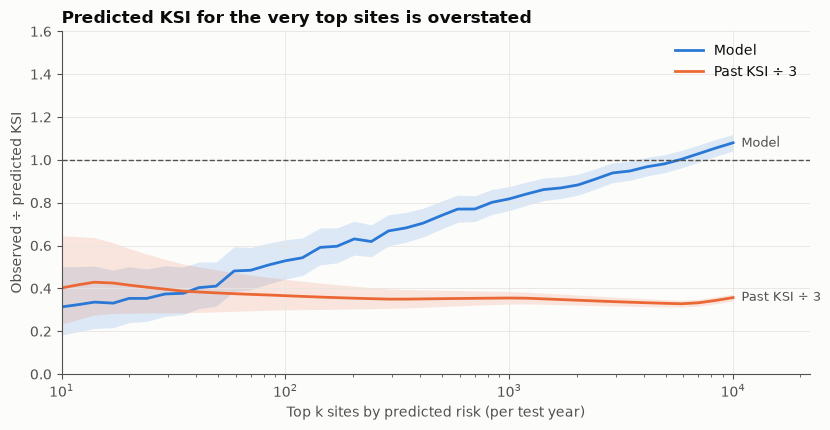

In [10]:
ks = np.unique(np.round(np.logspace(1, 4, 40)).astype(int))

rows = []

for name in ["5 NB: crash history (tiers)", "1 past KSI (baseline)"]:

    by_year = list(predictions[name].groupby("year"))

    for k in ks:

        pred_total, obs_total = np.sum([top_k_totals(d["ksi"], d["pred"], k) for _, d in by_year], axis=0)

        rows.append({"model": name, "k": k, "pred": pred_total, "obs": obs_total})

tail = pd.DataFrame(rows)

low, high = poisson_interval(tail["obs"])

tail = tail.assign(ratio=tail["obs"] / tail["pred"], low=low / tail["pred"], high=high / tail["pred"])



fig, ax = plt.subplots(figsize=(8.5, 4.4))

for name, color, label in [

    ("5 NB: crash history (tiers)", MODEL, "Model"),

    ("1 past KSI (baseline)", PRACTICE, "Past KSI ÷ 3"),

]:

    d = tail[tail["model"] == name]

    ax.fill_between(d["k"], d["low"], d["high"], color=color, alpha=0.15, linewidth=0)

    ax.plot(d["k"], d["ratio"], color=color, linewidth=2, label=label)

    ax.annotate(label, (d["k"].iloc[-1], d["ratio"].iloc[-1]), xytext=(6, 0),

                textcoords="offset points", va="center", fontsize=9, color=INK_2)

ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)

ax.set_xscale("log")

ax.set_xlim(ks.min(), ks.max() * 2.2)

ax.set_ylim(0, 1.6)

ax.set_xlabel("Top k sites by predicted risk (per test year)")

ax.set_ylabel("Observed ÷ predicted KSI")

ax.legend(frameon=False, loc="upper right")

ax.set_title("Predicted KSI for the very top sites is overstated")

fig.tight_layout()

tail[tail["k"].isin([10, 25, 100, 250, 1000, 10000]) | tail["k"].isin(ks[[0, 9, 19, 29, 39]])].round(2)

## Risk score for every site

Expected KSI crashes in the year after the data ends, from the severity-tier model above (the latest year's fixed effect is carried forward). The file is written to `experiments/outputs/`, which git ignores.

In [11]:
risk = (

    scoring[["site_id", "year", "ksi_lag3", "injury_lag3", "crashes_lag3", "highway_share", "camera_site"]]

    .assign(expected_ksi=final.predict(scoring))

    .merge(sites[["site_id", "x", "y", "latitude", "longitude", "n_points", "span_ft"]], on="site_id")

    .sort_values("expected_ksi", ascending=False)

    .assign(rank=lambda d: range(1, len(d) + 1))

)

out_dir = Path("outputs")

out_dir.mkdir(exist_ok=True)

risk.to_parquet(out_dir / f"q1_site_risk_{risk['year'].iloc[0]}.parquet")

risk.head(25)

,site_id,year,ksi_lag3,injury_lag3,crashes_lag3,highway_share,camera_site,expected_ksi,x,y,latitude,longitude,n_points,span_ft,rank
0,0,2026,6.0,83.0,172.0,0.298,False,3.460,1.008e+06,253289.177,40.862,-73.913,3,17.856,1
19,19,2026,2.0,72.0,143.0,0.515,True,2.939,1.005e+06,182837.129,40.668,-73.926,10,79.056,2
4694,4694,2026,4.0,59.0,114.0,0.255,False,2.330,1.009e+06,232440.127,40.805,-73.912,8,131.246,3
3,3,2026,1.0,57.0,121.0,0.000,True,2.291,1.013e+06,185481.811,40.676,-73.897,6,73.700,4
1,1,2026,1.0,73.0,195.0,1.000,False,2.227,9.737e+05,161065.280,40.609,-74.038,1,0.000,5
272,272,2026,2.0,63.0,119.0,0.000,False,2.113,1.012e+06,235544.486,40.813,-73.898,4,101.749,6
5,5,2026,2.0,59.0,109.0,0.000,True,2.086,1.015e+06,179232.971,40.659,-73.891,7,57.804,7
86,86,2026,3.0,53.0,131.0,0.573,False,2.053,1.052e+06,217065.639,40.762,-73.757,6,54.389,8
175,175,2026,3.0,67.0,121.0,0.008,True,2.045,1.013e+06,236519.334,40.816,-73.895,3,65.355,9
73,73,2026,2.0,91.0,153.0,0.795,False,1.958,1.060e+06,198479.540,40.711,-73.728,4,44.835,10


**Reading Figures 3 and 4.** Equal-size deciles made the model look well calibrated, but finer bins show an S-shaped pattern: the lowest-risk half of sites is over-predicted (observed ≈ 0.55× predicted), the 80th–98th percentiles are under-predicted by 20–35%, and the top 0.1% is over-predicted about 2×. Down the list, observed ÷ predicted for the top-k sites rises from about 0.3 (top 10) to 0.5 (top 100) and 0.8 (top 1,000). It reaches 1 only around the top 5,000 sites.

So **the ranking is useful but the expected counts for top sites are not forecasts**: the very top is partly selected for noise, the same regression to the mean that inflates past-KSI rankings. The past-KSI rule is worse still: it over-predicts about 2.8× at every list length.

A fix belongs in the model (e.g. shrinking extreme predictions, or a more flexible form than log1p-linear) and should be re-checked with these two figures.

## Figure 5: The 100 highest-risk sites

Gray dots are all ~89k crash sites; together they trace the street network. Blue dots are the top 100 by expected KSI, sized by expected KSI, with ranks 1–10 labeled.

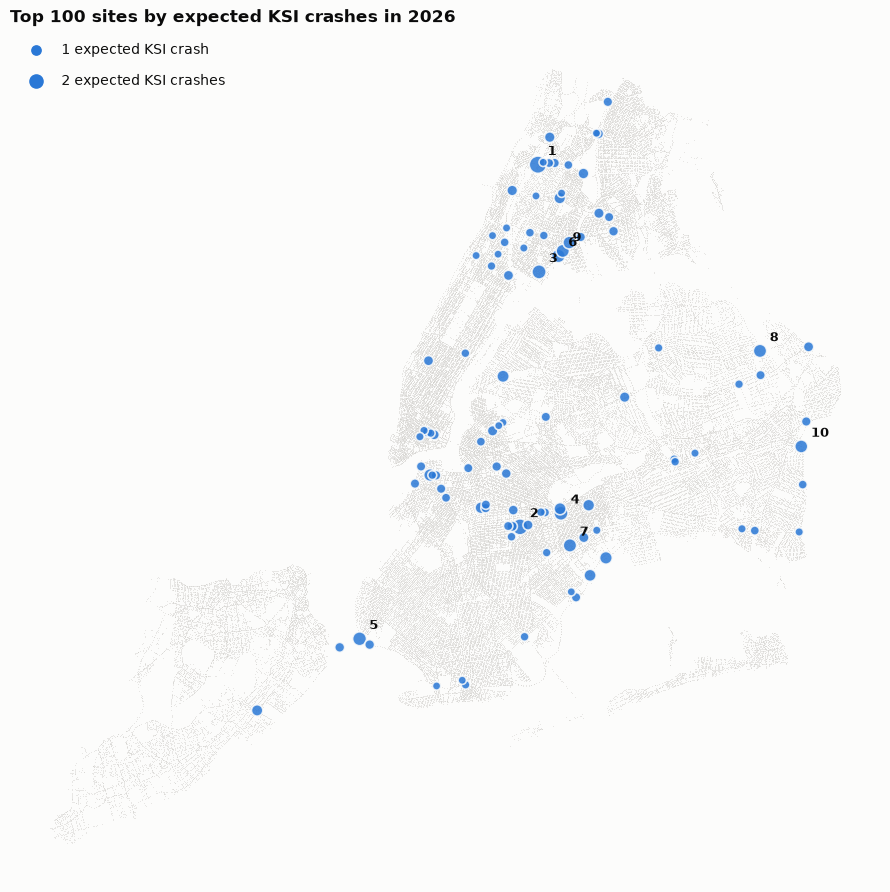

In [12]:
N_TOP = 100

top = risk.head(N_TOP)



def base_map(ax):

    ax.scatter(sites["x"], sites["y"], s=0.15, color=CONTEXT, linewidths=0, rasterized=True)

    ax.set_aspect("equal")

    ax.axis("off")



fig, ax = plt.subplots(figsize=(9, 9))

base_map(ax)

ax.scatter(top["x"], top["y"], s=top["expected_ksi"] * 45, color=MODEL, alpha=0.85,

           edgecolor=SURFACE, linewidth=1.2, zorder=3)

for _, r in top.head(10).iterrows():

    ax.annotate(str(r["rank"]), (r["x"], r["y"]), xytext=(7, 7), textcoords="offset points",

                fontsize=9, fontweight="bold", color=INK)

for size in [1, 2]:

    ax.scatter([], [], s=size * 45, color=MODEL, label=f"{size} expected KSI crash" + ("es" if size > 1 else ""))

ax.legend(loc="upper left", frameon=False, labelspacing=1.2)

ax.set_title(f"Top {N_TOP} sites by expected KSI crashes in {risk['year'].iloc[0]}")

fig.tight_layout()

In [13]:
top.head(10)[["rank", "expected_ksi", "ksi_lag3", "crashes_lag3", "camera_site", "latitude", "longitude"]]

,rank,expected_ksi,ksi_lag3,crashes_lag3,camera_site,latitude,longitude
0,1,3.460,6.0,172.0,False,40.862,-73.913
19,2,2.939,2.0,143.0,True,40.668,-73.926
4694,3,2.330,4.0,114.0,False,40.805,-73.912
3,4,2.291,1.0,121.0,True,40.676,-73.897
1,5,2.227,1.0,195.0,False,40.609,-74.038
272,6,2.113,2.0,119.0,False,40.813,-73.898
5,7,2.086,2.0,109.0,True,40.659,-73.891
86,8,2.053,3.0,131.0,False,40.762,-73.757
175,9,2.045,3.0,121.0,True,40.816,-73.895
73,10,1.958,2.0,153.0,False,40.711,-73.728


## Figure 6: Which sites does each method pick?

The top 100 sites by past KSI (current practice) next to the top 100 by the model. Many sites tie on past KSI, so ties at the cutoff are broken by site id. Circled sites are on both lists.

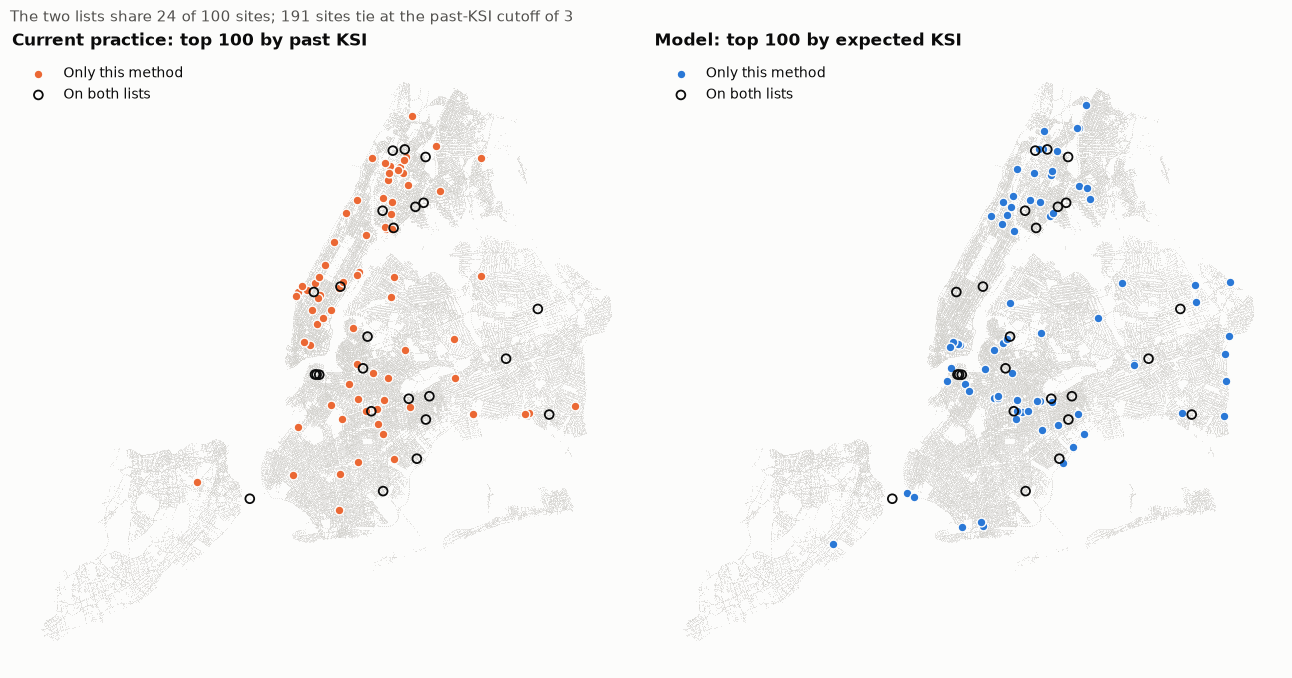

In [14]:
by_practice = risk.sort_values(["ksi_lag3", "site_id"], ascending=[False, True]).head(N_TOP)

both = set(by_practice["site_id"]) & set(top["site_id"])

cutoff = by_practice["ksi_lag3"].min()

tied = (risk["ksi_lag3"] == cutoff).sum()



fig, axes = plt.subplots(1, 2, figsize=(13, 7))

for ax, picks, color, title in [

    (axes[0], by_practice, PRACTICE, "Current practice: top 100 by past KSI"),

    (axes[1], top, MODEL, "Model: top 100 by expected KSI"),

]:

    base_map(ax)

    shared = picks["site_id"].isin(both)

    ax.scatter(picks.loc[~shared, "x"], picks.loc[~shared, "y"], s=40, color=color,

               edgecolor=SURFACE, linewidth=1, zorder=3, label="Only this method")

    ax.scatter(picks.loc[shared, "x"], picks.loc[shared, "y"], s=40, facecolor="none",

               edgecolor=INK, linewidth=1.3, zorder=4, label="On both lists")

    ax.legend(loc="upper left", frameon=False)

    ax.set_title(title)

fig.suptitle(f"The two lists share {len(both)} of {N_TOP} sites; {tied:,} sites tie at the "

             f"past-KSI cutoff of {cutoff:.0f}", x=0.01, ha="left", fontsize=11, color=INK_2)

fig.tight_layout()